# Optional · When a tree predicts a number

**Day 3 slide** 22. **Trainer guide cards** 74–76.

**The problem.** Apartment prices are numbers. What happens when
a decision tree is asked for the price of an apartment larger than
any size it saw while learning?

**What we’re doing.** Train a short tree and a straight line on
the same apartment sizes, then draw their guesses for larger sizes.

**Why.** This is a quick comparison with today’s classification
trees. A classification tree guesses a label such as left or stayed.
A regression tree uses the average of the numbers in its final box.

Run the cells from the top with **Shift + Enter**.

## Setup · Find the property file

Run the imports and folder check as written. The file contains
the synthetic property examples supplied with the course.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

here = Path.cwd()
data = next((p / "data" for p in (here, *here.parents)
             if (p / "data" / "property_valuations.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

## 1 · Guess a value from the size

**What we’re doing.** Train a regression tree and a line on apartment sizes between 700 and 1,600 square feet. Ask both for guesses up to 2,300 square feet.

**Why.** A regression tree gives the average value in its final box. Once a new size follows the same path to the same box, the prediction stays flat. A line keeps moving with size.

**Look for.** The shaded area is outside the training size range. The tree is flat there. The line can extend, and checking larger recorded properties would show whether its added trend helps.

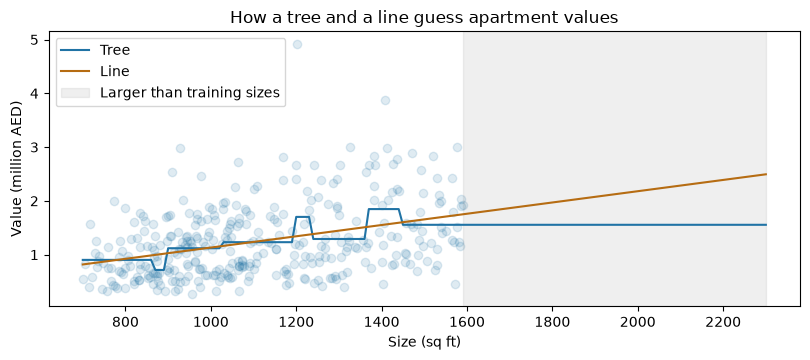

In [2]:
columns = ["emirate", "property_type", "size_sqft", "valuation_aed"]
properties = pd.read_csv(data / "property_valuations.csv", usecols=columns).dropna()
apartments = properties.query("emirate == 'Dubai' and property_type == 'Apartment'")
example = apartments[apartments["size_sqft"].between(700, 1600)].sample(350, random_state=42)
clue = ["size_sqft"]
value_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=12).fit(example[clue], example["valuation_aed"])
line = LinearRegression().fit(example[clue], example["valuation_aed"])
sizes = pd.DataFrame({"size_sqft": range(700, 2301, 10)})
fig, ax = plt.subplots(figsize=(8.2, 3.7))
ax.scatter(example["size_sqft"], example["valuation_aed"] / 1e6, alpha=.14, color="#2073a5")
ax.plot(sizes["size_sqft"], value_tree.predict(sizes) / 1e6, label="Tree", color="#2073a5")
ax.plot(sizes["size_sqft"], line.predict(sizes) / 1e6, label="Line", color="#b66c12")
ax.axvspan(example["size_sqft"].max(), 2300, alpha=.12, color="gray", label="Larger than training sizes")
ax.set(title="How a tree and a line guess apartment values", xlabel="Size (sq ft)", ylabel="Value (million AED)")
ax.legend()
plt.tight_layout()
plt.show()

## 2 · Give the tree a smaller job

**What we’re doing.** Let the line make the first guess. Teach a
tree the difference between the recorded price and that guess.
Then add the tree’s correction to the line’s guess.

**Why.** The line supplies a trend and the tree supplies a local
correction. A relative target is a related idea. It expresses
the correction as a share of the starting guess.

**Look for.** The combined estimate can change for larger sizes
because the line keeps changing. We would need examples of larger
apartments to check how good those guesses are.

In [3]:
training_price = example["valuation_aed"]
line_guess = line.predict(example[clue])
correction = DecisionTreeRegressor(max_depth=3, random_state=42)
correction.fit(example[clue], training_price - line_guess)

larger = pd.DataFrame({"size_sqft": [1800, 2200]})
larger["Tree on its own"] = value_tree.predict(larger[clue]).round()
larger["Line plus tree correction"] = (line.predict(larger[clue]) + correction.predict(larger[clue])).round()
larger

,size_sqft,Tree on its own,Line plus tree correction
0,1800,1555452.0,1864710.0
1,2200,1555452.0,2283743.0


### Your turn

Point to the grey area in the chart. Explain why the tree on its
own gives the same answer for both large sizes.

[Back to the L3.4 churn classification walkthrough](L3.4_Churn_Classification_Walkthrough.ipynb)